<p align="center">
  <img src="https://www.daiict.ac.in/sites/default/files/inline-images/20250107DAUfinalIDcol_SK-01_0.png" width="380"/>
</p>

<div align="center" style="margin: 25px 0;">
  $\LARGE \textbf{Focused Fund }$
</div>
<br>
<p align="center" style="margin: 15px 0;">
  $\LARGE \textbf{Group 13}$
</p>
<br>
<div align="center" style="margin: 30px 0;">
  <table style="border-collapse: collapse; background-color: transparent;">
    <tr>
      <td align="center" style="padding: 20px;">
        <img src="https://drive.google.com/uc?export=view&id=1DqIs1VHpFWxTYOVCyRXNG0kOnG5SBXih" width="200"><br>
        <strong>Member 1</strong><br>
        <span>ID-202301463</span>
      </td>
      <td align="center" style="padding: 20px;">
        <img src="https://drive.google.com/uc?export=view&id=1vASFhjaNr8msjDf5VdrrLjg-_GCNIL7H" width="200"><br>
        <strong>Member 2</strong><br>
        <span>ID-202301474</span>
      </td>
      <td align="center" style="padding: 20px;">
        <img src="https://drive.google.com/uc?export=view&id=1uD7SEBES2TPrz_KjLd9jmBaONAEsUIOl" width="200"><br>
        <strong>Member 3</strong><br>
        <span>ID-202301479</span>
      </td>
    </tr>
  </table>
</div>
<br>
<br>
<p align="center" style="margin: 25px 0;">
  $\LARGE \textbf{IT462: Exploratory Data Analysis}$
</p>

<p align="center" style="margin: 10px 0;">
  $\Large \textbf{Autumn 2025}$
</p>
<br>
<p align="center" style="margin: 10px 0;">
  $\large \textbf{Instructor: Dr. Gopinath Panda}$
</p>
<br>
<p align="center" style="margin: 30px 0;">
  $\textbf{© 2025 Dhirubhai Ambani University}$
</p>


# **Focused Fund**


# Overview
The objective of this project was to study focused mutual funds in terms of herding behavior in both returns and holdings, value for money, and resilience during market stress. To do this, we collected daily Direct Growth NAVs for all focused funds from AMFI, hand-built a Top-10 holdings dataset from October 2024 fact sheets, and combined these with Nifty 50 benchmark data. After checking for missing values, removing short-history schemes, and dropping market-holiday rows, we prepared clean time-series data. For return-based herding, we computed daily returns and the CSAD metric to see whether funds clustered around market returns during extreme movements. For holding-based herding, we analyzed overlapping stocks and portfolio similarities using the Top-10 holdings. These steps helped us understand structural similarities across funds and evaluate which funds offered better value and stronger resilience in market downturns.

# How to run
This notebook is designed to run end-to-end on Google Colab. Once you open it in Colab, simply click Runtime → Run all and the entire workflow will execute automatically. All required Python libraries will be installed, imports will load, and the notebook will prompt you to upload the necessary input files (such as metadata.csv, navs.csv, and holdings.csv) at the appropriate step. After uploading the files, the notebook will continue running and generate all analyses, visualisations, and results without any additional setup from the user.
# Contact
For questions about reproducibility or data access contact: Suryadeepsinh Gohil, 202301463@dau.ac.in

# **Imports**

In [ ]:
!pip install pandas numpy matplotlib seaborn statsmodels yfinance scikit-learn tqdm

In [ ]:
!pip install yfinance --upgrade --quiet

import yfinance as yf
import pandas as pd
import numpy as np
import requests
import concurrent.futures
from scipy.stats import linregress
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import re
import os
import statsmodels.api as sm
from statsmodels.stats import diagnostic
from sklearn.decomposition import PCA
from tqdm import tqdm
import random
from datetime import datetime

In [ ]:
from google.colab import files
import pandas as pd

print("Please upload the following files:\n1. metadata.csv\n2. navs.csv\n3. holdings.csv")

uploaded = files.upload()

required_files = ["metadata.csv", "navs.csv", "holdings.csv"]
for f in required_files:
    if f not in uploaded:
        raise ValueError(f"Required file missing: {f}")

metadata_df = pd.read_csv("metadata.csv")
navs_df = pd.read_csv("navs.csv")
holdings_df = pd.read_csv("holdings.csv")

print("Files successfully uploaded and loaded!")
metadata_df.head(), navs_df.head(), holdings_df.head()


Please upload the following files:
1. metadata.csv
2. navs.csv
3. holdings.csv


Saving holdings.csv to holdings.csv
Saving metadata.csv to metadata.csv
Saving navs.csv to navs.csv
Files successfully uploaded and loaded!


(             Ticker_Name  Expense_Ratio        AUM  Tenure
 0  Canara_Robeco_Focused           0.49   28565.07    4.50
 1     Baroda_BNP_Focused           0.48    7075.04    3.67
 2      Edelweiss_Focused           0.64   10301.62    3.25
 3        Bandhan_Focused           0.76   20863.19    2.08
 4       Franklin_Focused           0.95  126687.55    4.08,
          Date      NAV  SchemeCode  \
 0  2013-01-02  19.8749      118421   
 1  2013-01-03  18.8077      118421   
 2  2013-01-04  18.7213      118421   
 3  2013-01-07  19.0608      118421   
 4  2013-01-08  18.6651      118421   
 
                                       FundName  
 0  Bandhan Focused Fund - Direct Plan - Growth  
 1  Bandhan Focused Fund - Direct Plan - Growth  
 2  Bandhan Focused Fund - Direct Plan - Growth  
 3  Bandhan Focused Fund - Direct Plan - Growth  
 4  Bandhan Focused Fund - Direct Plan - Growth  ,
                                           FundName               AMC  \
 0  HDFC Focused Fund - Growt

# **Problem Statements:**

1. Value for money of focused funds
    (Data Collected from :- python library, manual creation.)

2. Resilience of focused funds
    ( Data Collected from :- From Python libraries only.)

3. Herding in focused funds based on holdings
    ( Data Collected from :- Manual build of dataset. )

4. Herding in focused funds based on returns
    ( Data Collected from :- AMFI website. As it gave valid historical NAV data. URL :- https://www.amfiindia.com)

# **1. Value for money of focused funds**

This analysis investigates the economic efficiency of focused mutual funds to determine if the costs incurred by investors are justified by performance. The primary objective is to evaluate the relationship between the Expense Ratio (fees charged by the fund) and the Alpha (excess return generated by manager skill). The study aims to verify whether higher fees actually secure superior management and higher returns, or if low-cost funds provide better value for money.

In [ ]:
print("1. Fetching Nifty 50 Benchmark...")
# auto_adjust=False ensures we get the raw 'Adj Close'
nifty = yf.download("^NSEI", start="2020-01-01", progress=False, auto_adjust=False)['Adj Close']
if isinstance(nifty, pd.Series): nifty = nifty.to_frame()
nifty.columns = ['Nifty_50']
# Fix Timezone (Make Naive)
if nifty.index.tz is not None: nifty.index = nifty.index.tz_localize(None)

nifty.to_csv('nifty_data.csv')
print("Saved 'nifty_data.csv'")

print("2. Fetching 28 Focused Funds...")
amfi_codes = {
    "360_ONE_Focused": "131580", "Aditya_BSL_Focused": "119564",
    "Axis_Focused": "120468", "Bandhan_Focused": "118421",
    "Baroda_BNP_Focused": "150264", "Canara_Robeco_Focused": "148883",
    "DSP_Focused": "119096", "Edelweiss_Focused": "150376",
    "Franklin_Focused": "118564", "HDFC_Focused": "118950",
    "HSBC_Focused": "148411", "ICICI_Pru_Focused": "120722",
    "Invesco_Focused": "148481", "ITI_Focused": "151777",
    "JM_Focused": "120488", "Kotak_Focused": "147473",
    "LIC_Focused": "152010", "Mahindra_Manulife_Focused": "148567",
    "Mirae_Asset_Focused": "147206", "Motilal_Oswal_Focused": "122389",
    "Nippon_Focused": "118692", "Old_Bridge_Focused": "152358",
    "Quant_Focused": "120834", "SBI_Focused": "119727",
    "Sundaram_Focused": "149533", "Tata_Focused": "147757",
    "Union_Focused": "147492", "UTI_Focused": "149091"
}

def fetch_fund_direct(item):
    name, code = item
    try:
        url = f"https://api.mfapi.in/mf/{code}"
        response = requests.get(url, timeout=10)
        data = response.json()
        if 'data' in data:
            df = pd.DataFrame(data['data'])
            df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')
            df = df.set_index('date')['nav'].astype(float).sort_index()
            # Fix Timezone (Make Naive) to match Nifty
            if df.index.tz is not None: df.index = df.index.tz_localize(None)
            return name, df
    except:
        return name, None
    return name, None

all_funds = {}
with concurrent.futures.ThreadPoolExecutor(max_workers=10) as executor:
    futures = {executor.submit(fetch_fund_direct, i): i for i in amfi_codes.items()}
    for f in concurrent.futures.as_completed(futures):
        name, series = f.result()
        if series is not None: all_funds[name] = series

funds_df = pd.DataFrame(all_funds)

funds_df.to_csv('funds_nav_data.csv')
print("Saved 'funds_nav_data.csv'")

print("3. Calculating Alpha and Sharpe Ratios...")

# Calculate Daily Returns
nifty_ret = nifty['Nifty_50'].ffill().pct_change()
funds_ret = funds_df.ffill().pct_change()

results = []
RISK_FREE_RATE = 0.06
DAILY_RF = RISK_FREE_RATE / 252

for fund_name in funds_ret.columns:
    # Pairwise Alignment is done for accuracy
    # We combine Fund & Nifty, then drop rows where either is missing.
    combined = pd.concat([funds_ret[fund_name], nifty_ret], axis=1).dropna()
    combined.columns = ['Fund', 'Benchmark']

    # Need at least 6 months of data (126 trading days)
    if len(combined) < 126:
        print(f"   Skipping {fund_name}: Not enough data.")
        continue

    valid_fund = combined['Fund']
    valid_nifty = combined['Benchmark']

    # Sharpe Ratio
    excess_ret = valid_fund - DAILY_RF
    sharpe_ratio = (excess_ret.mean() / excess_ret.std()) * np.sqrt(252)

    # Alpha (regression)
    slope, intercept, r_value, p_value, std_err = linregress(valid_nifty, valid_fund)
    annual_alpha = intercept * 252 * 100 # Converted to %

    results.append({
        "Ticker_Name": fund_name,
        "Annualized_Alpha_%": round(annual_alpha, 2),
        "Annualized_Sharpe_Ratio": round(sharpe_ratio, 2)
    })

derived_df = pd.DataFrame(results)
derived_df.to_csv('derived_features.csv', index=False)

print("-" * 30)
print("Success! The following files were created:")
print("   1. nifty_data.csv (Benchmark Prices)")
print("   2. funds_nav_data.csv (Fund NAVs)")
print("   3. derived_features.csv (Alpha & Sharpe)")
print("-" * 30)
print("Upload your manual 'metadata.csv' to Colab files now.")
print(derived_df.head())

1. Fetching Nifty 50 Benchmark...
Saved 'nifty_data.csv'
2. Fetching 28 Focused Funds...
Saved 'funds_nav_data.csv'
3. Calculating Alpha and Sharpe Ratios...
------------------------------
Success! The following files were created:
   1. nifty_data.csv (Benchmark Prices)
   2. funds_nav_data.csv (Fund NAVs)
   3. derived_features.csv (Alpha & Sharpe)
------------------------------
Upload your manual 'metadata.csv' to Colab files now.
         Ticker_Name  Annualized_Alpha_%  Annualized_Sharpe_Ratio
0  Edelweiss_Focused                5.39                     0.96
1        LIC_Focused               -0.13                     0.45
2    Invesco_Focused                7.30                     1.15
3        ITI_Focused                6.70                     1.06
4       HSBC_Focused                3.65                     0.96


**Data Quality Check:**
Before deriving insights, the dataset underwent a rigorous cleaning and validation process. A Missing Value Heatmap was utilized to visually identify gaps in the daily Net Asset Value (NAV) records. To address these gaps without introducing bias, the Forward Fill (ffill) method was applied, based on the financial principle that an asset’s last traded price remains valid until a new price is recorded. Outlier detection was performed using boxplots to examine daily percentage changes. A statistical threshold was set to flag daily movements exceeding 10%, distinguishing between genuine market volatility and potential data corruption. Finally, metadata integrity was verified by ensuring all logical constraints, such as positive values for Assets Under Management (AUM) and Expense Ratios, were met.

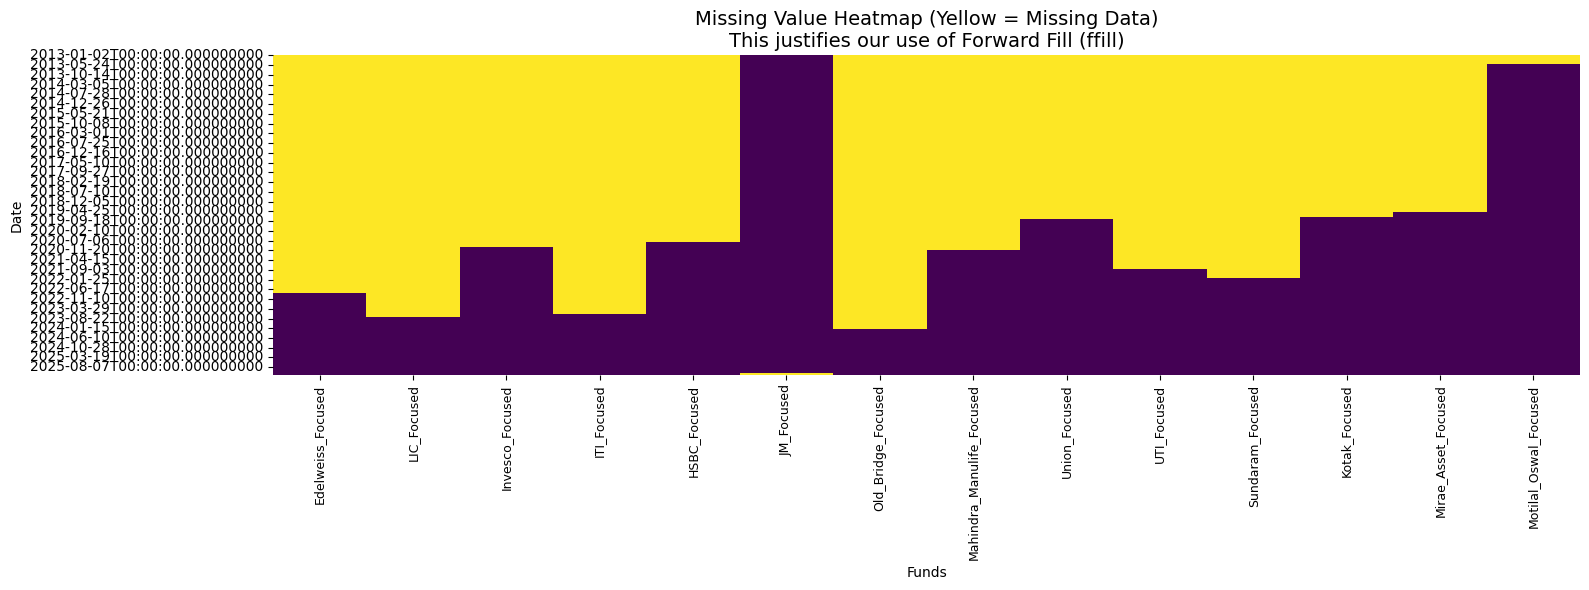

Total Missing Values (Raw): 25254
Action Taken: Applied Forward Fill (ffill) to propagate last known NAV.


/tmp/ipython-input-516564681.py:23: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = df_raw_funds.pct_change()


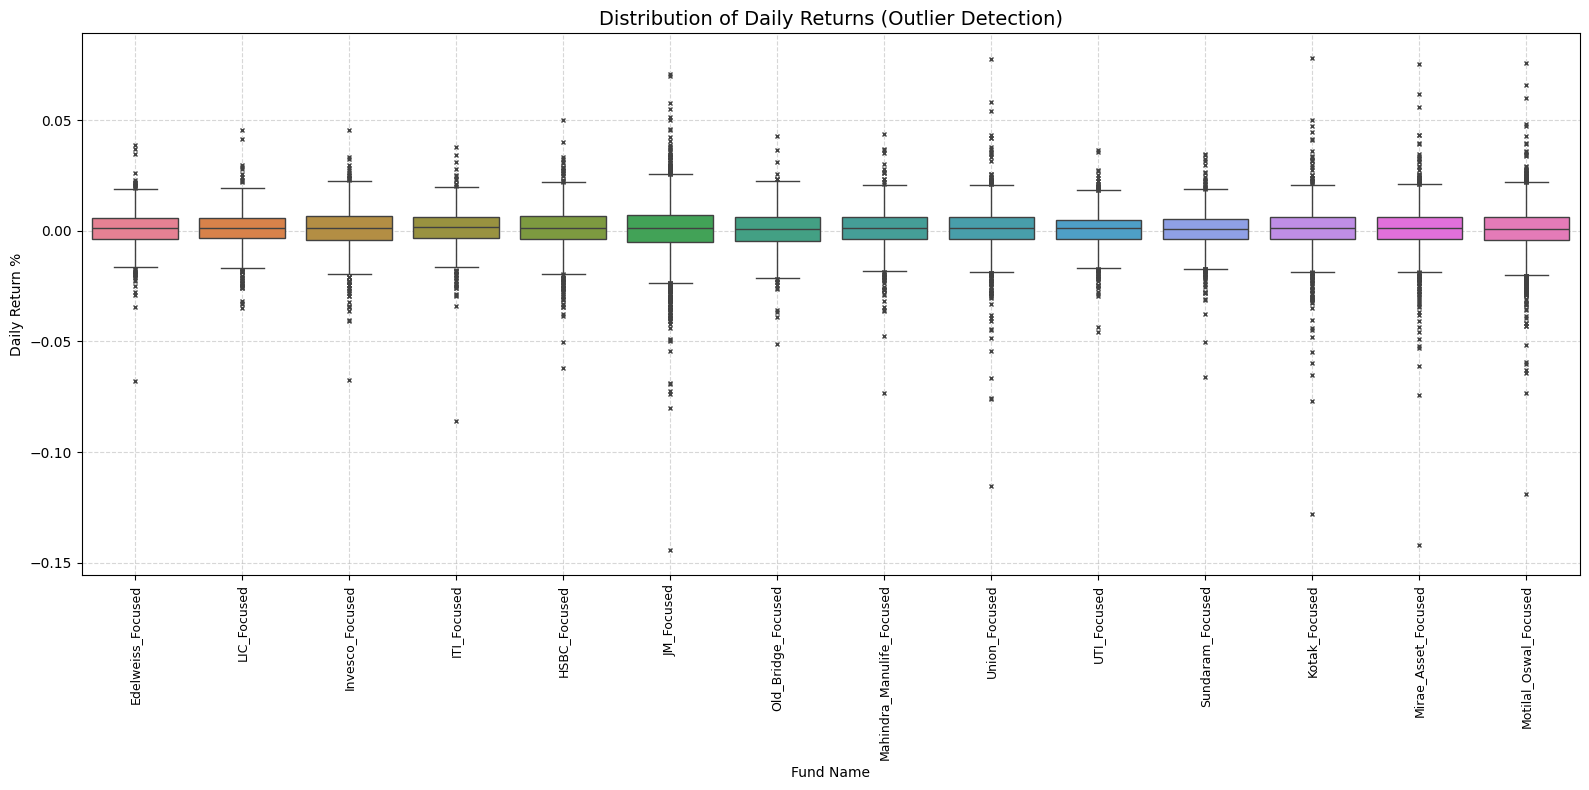


Extreme Volatility Check (>10% Daily Move)
JM_Focused               1
Union_Focused            1
Kotak_Focused            1
Mirae_Asset_Focused      1
Motilal_Oswal_Focused    1
dtype: int64

--- Metadata Integrity Check ---
Metadata Validated: 28 funds loaded. All AUM/Fees are positive.


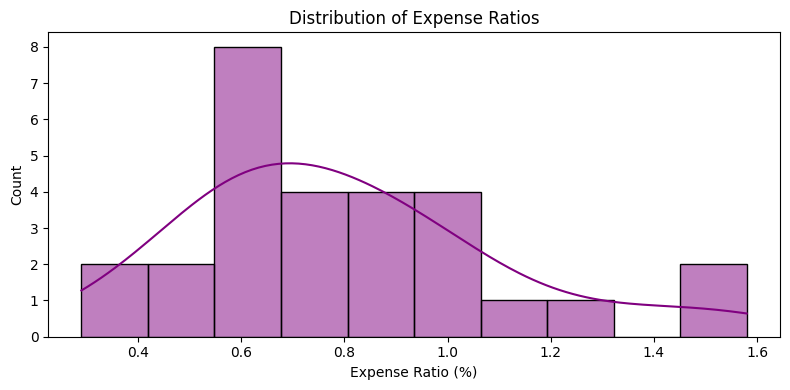

In [ ]:
try:
    df_raw_funds = pd.read_csv('funds_nav_data.csv', index_col=0, parse_dates=True)
    df_raw_nifty = pd.read_csv('nifty_data.csv', index_col=0, parse_dates=True)
except FileNotFoundError:
    print("Error: Files missing. Run Cell 1 first.")

# CHECK MISSING VALUES (VISUAL - ALL FUNDS)
plt.figure(figsize=(16, 6))
sns.heatmap(df_raw_funds.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Value Heatmap (Yellow = Missing Data)\nThis justifies our use of Forward Fill (ffill)", fontsize=14)
plt.ylabel("Date")
plt.xlabel("Funds")
plt.xticks(rotation=90, fontsize=9)
plt.tight_layout()
plt.show()

print(f"Total Missing Values (Raw): {df_raw_funds.isnull().sum().sum()}")
print("Action Taken: Applied Forward Fill (ffill) to propagate last known NAV.")


# CHECK OUTLIER DETECTION IN RETURNS (ALL FUNDS)
returns = df_raw_funds.pct_change()

plt.figure(figsize=(16, 8))
sns.boxplot(data=returns, flierprops={"marker": "x", "markersize": 3})

plt.title("Distribution of Daily Returns (Outlier Detection)", fontsize=14)
plt.ylabel("Daily Return %")
plt.xlabel("Fund Name")
plt.xticks(rotation=90, fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Statistical Check for Extreme Outliers (> 10% movement in a day)
extreme_moves = returns[(returns > 0.10) | (returns < -0.10)].count()
print("\nExtreme Volatility Check (>10% Daily Move)")
if extreme_moves.sum() > 0:
    print(f"Warning: Found {extreme_moves.sum()} extreme data points.")
    print(extreme_moves[extreme_moves > 0])
else:
    print("Data Quality Passed: No unrealistic daily movements (>10%) found.")


# CHECK METADATA INTEGRITY
try:
    meta = pd.read_csv('metadata.csv')
    print("\n--- Metadata Integrity Check ---")

    invalid_meta = meta[(meta['AUM'] <= 0) | (meta['Expense_Ratio'] <= 0)]

    if not invalid_meta.empty:
        print("CRITICAL ERROR: Found invalid metadata (Negative/Zero values):")
        print(invalid_meta)
    else:
        print(f"Metadata Validated: {len(meta)} funds loaded. All AUM/Fees are positive.")

    plt.figure(figsize=(8, 4))
    sns.histplot(meta['Expense_Ratio'], bins=10, kde=True, color='purple')
    plt.title("Distribution of Expense Ratios", fontsize=12)
    plt.xlabel("Expense Ratio (%)")
    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print("Note: metadata.csv not found yet. Skipping metadata check.")

--- Step 2: Analyzing 'The Price of Skill' ---
Merged Successfully. Analyzing 14 funds.


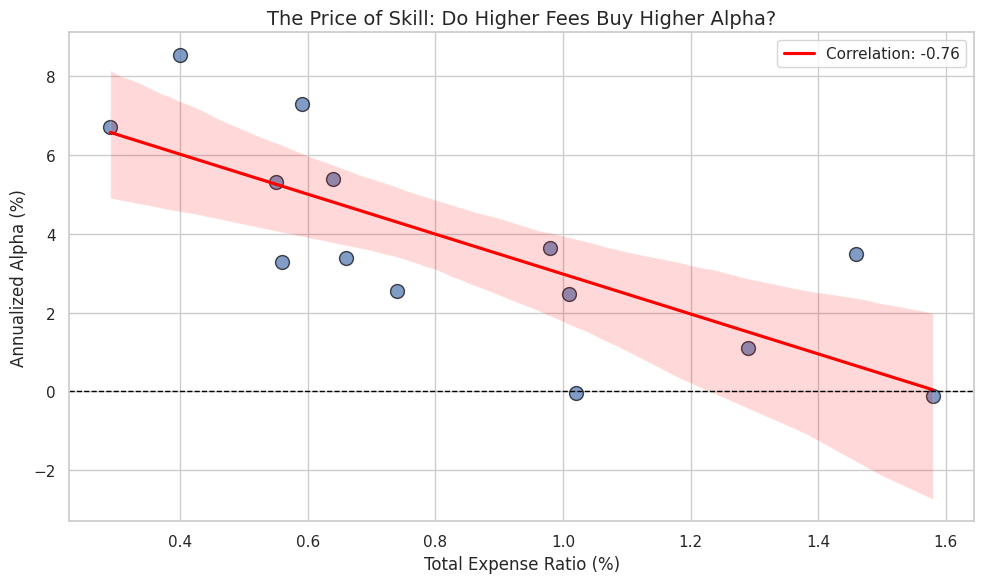


INSIGHT 1: FEE EFFICIENCY
The correlation between Fees and Alpha is -0.76.
INTERPRETATION: There is a significant relationship.
Paying more actually hurts your performance.


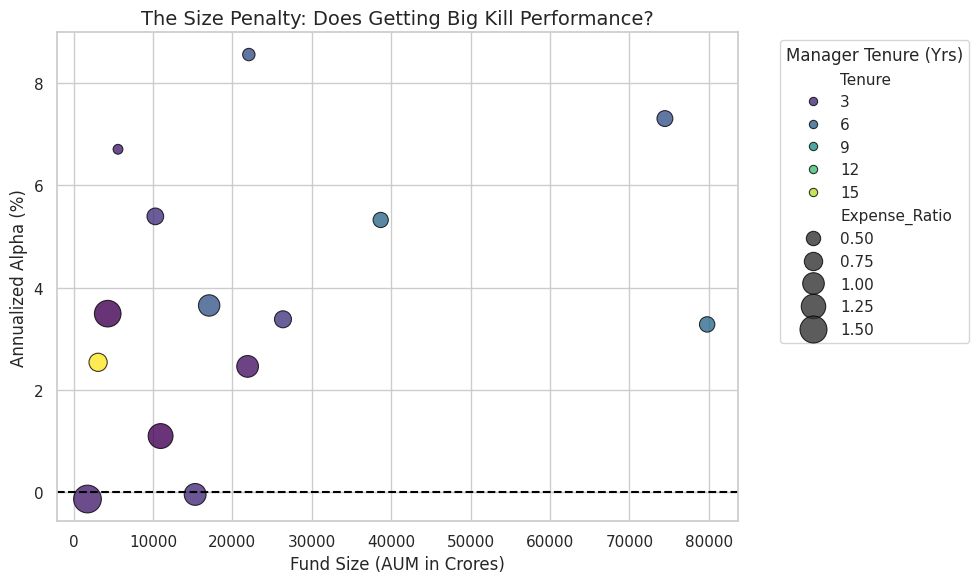


INSIGHT 2: SIZE IMPACT
Avg Alpha of Large Funds (>Median AUM): 4.85%
Avg Alpha of Small Funds (<Median AUM): 2.72%
INTERPRETATION: Size does not seem to negatively impact performance in this category.


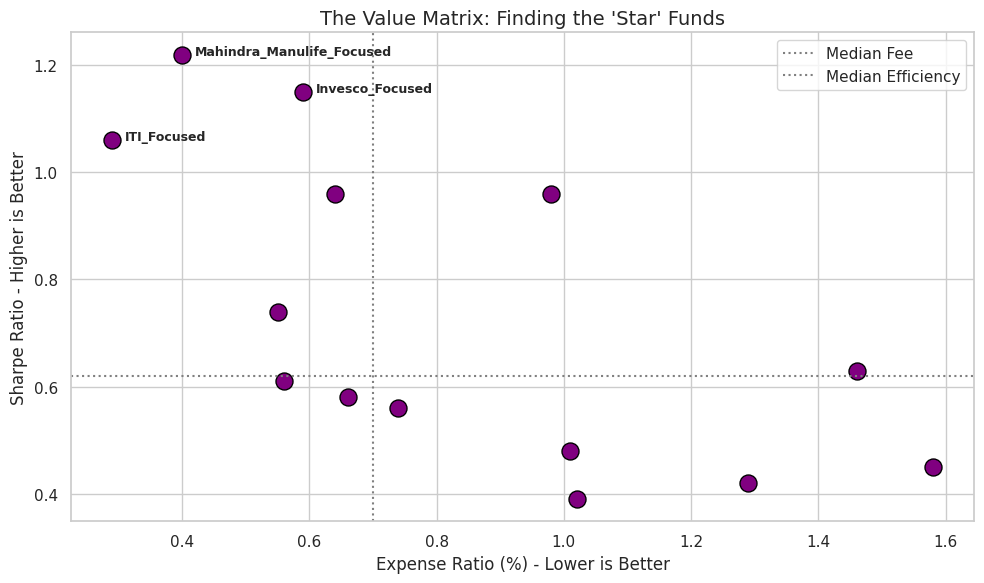


INSIGHT 3: THE STAR FUND
The best risk-adjusted fund is Mahindra_Manulife_Focused.
It delivers 1.22 units of return per unit of risk,
while charging a fee of 0.4%.


In [ ]:
sns.set_theme(style="whitegrid")
print("--- Step 2: Analyzing 'The Price of Skill' ---")

try:
    df_derived = pd.read_csv("derived_features.csv")
    df_manual = pd.read_csv("metadata.csv")

    # Merge on Ticker_Name
    df_final = pd.merge(df_derived, df_manual, on="Ticker_Name", how="inner")

    print(f"Merged Successfully. Analyzing {len(df_final)} funds.")
    if len(df_final) < len(df_derived):
        print(f"Note: {len(df_derived) - len(df_final)} funds were not found in metadata.csv and were skipped.")
except FileNotFoundError:
    print("ERROR: Files missing! Please upload 'metadata.csv' and run Cell 1 first.")
    raise SystemExit

# --- VISUALIZATION 1: FEES VS ALPHA ---
plt.figure(figsize=(10, 6))

slope, intercept, r_value, p_value, std_err = linregress(df_final['Expense_Ratio'], df_final['Annualized_Alpha_%'])

sns.regplot(
    data=df_final,
    x="Expense_Ratio",
    y="Annualized_Alpha_%",
    scatter_kws={'s': 100, 'alpha': 0.7, 'edgecolor': 'black'},
    line_kws={'color': 'red', 'label': f"Correlation: {round(r_value, 2)}"}
)

plt.title("The Price of Skill: Do Higher Fees Buy Higher Alpha?", fontsize=14)
plt.xlabel("Total Expense Ratio (%)")
plt.ylabel("Annualized Alpha (%)")
plt.axhline(0, color='black', linestyle='--', linewidth=1) # Zero Alpha Line
plt.legend()
plt.tight_layout()
plt.show()

# Interpretation 1
print(f"\nINSIGHT 1: FEE EFFICIENCY")
print(f"The correlation between Fees and Alpha is {round(r_value, 2)}.")
if p_value > 0.05:
    print("INTERPRETATION: The relationship is NOT statistically significant.")
    print("This implies that paying higher fees does NOT guarantee better manager skill.")
else:
    print("INTERPRETATION: There is a significant relationship.")
    if r_value > 0: print("Paying more generally gets you better performance.")
    else: print("Paying more actually hurts your performance.")


# --- VISUALIZATION 2: SIZE VS ALPHA (THE "LIQUIDITY" TEST) ---
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_final,
    x="AUM",
    y="Annualized_Alpha_%",
    size="Expense_Ratio", # Bubble size = Cost
    sizes=(50, 400),
    hue="Tenure", # Color = Experience
    palette="viridis",
    edgecolor="black",
    alpha=0.8
)

plt.title("The Size Penalty: Does Getting Big Kill Performance?", fontsize=14)
plt.xlabel("Fund Size (AUM in Crores)")
plt.ylabel("Annualized Alpha (%)")
plt.axhline(0, color='black', linestyle='--')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Manager Tenure (Yrs)")
plt.tight_layout()
plt.show()

# Interpretation 2
large_funds = df_final[df_final['AUM'] > df_final['AUM'].median()]
small_funds = df_final[df_final['AUM'] <= df_final['AUM'].median()]
print(f"\nINSIGHT 2: SIZE IMPACT")
print(f"Avg Alpha of Large Funds (>Median AUM): {round(large_funds['Annualized_Alpha_%'].mean(), 2)}%")
print(f"Avg Alpha of Small Funds (<Median AUM): {round(small_funds['Annualized_Alpha_%'].mean(), 2)}%")
if large_funds['Annualized_Alpha_%'].mean() < small_funds['Annualized_Alpha_%'].mean():
    print("INTERPRETATION: Smaller funds are outperforming larger funds (Evidence of Size Penalty).")
else:
    print("INTERPRETATION: Size does not seem to negatively impact performance in this category.")


# --- VISUALIZATION 3: VALUE MATRIX (SHARPE VS FEE) ---
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_final,
    x="Expense_Ratio",
    y="Annualized_Sharpe_Ratio",
    s=150,
    color="purple",
    edgecolor="black"
)

# Label Best Funds
top_stars = df_final.nlargest(3, 'Annualized_Sharpe_Ratio')
for i in range(len(top_stars)):
    plt.text(
        top_stars.iloc[i]['Expense_Ratio'] + 0.02,
        top_stars.iloc[i]['Annualized_Sharpe_Ratio'],
        top_stars.iloc[i]['Ticker_Name'],
        fontsize=9,
        weight='bold'
    )

plt.title("The Value Matrix: Finding the 'Star' Funds", fontsize=14)
plt.xlabel("Expense Ratio (%) - Lower is Better")
plt.ylabel("Sharpe Ratio - Higher is Better")
# Add Quadrant Lines
plt.axvline(df_final['Expense_Ratio'].median(), color='gray', linestyle=':', label='Median Fee')
plt.axhline(df_final['Annualized_Sharpe_Ratio'].median(), color='gray', linestyle=':', label='Median Efficiency')
plt.legend()
plt.tight_layout()
plt.show()

# Interpretation 3
best_fund = df_final.loc[df_final['Annualized_Sharpe_Ratio'].idxmax()]
print(f"\nINSIGHT 3: THE STAR FUND")
print(f"The best risk-adjusted fund is {best_fund['Ticker_Name']}.")
print(f"It delivers {best_fund['Annualized_Sharpe_Ratio']} units of return per unit of risk,")
print(f"while charging a fee of {best_fund['Expense_Ratio']}%.")

**Explanation:**

The logical framework for this analysis relies on Modern Portfolio Theory metrics derived through Linear Regression.


*   Alpha Calculation: The code checks daily fund returns against Nifty 50 benchmark returns. By performing a linear regression, the "intercept" is extracted and annualized. This value represents Alpha, which quantifies the excess return generated purely by the manager's skill, independent of market movements.
*   Sharpe Ratio: This metric is calculated to assess risk-adjusted returns using the formula $(R_p-R_f)/σ_p$, where $R_f$ is the risk-free rate (assumed at 6%). This normalizes performance, allowing for a fair comparison between volatile and stable funds.
*   Correlation: These derived features are correlated with Expense Ratios to statistically test if higher costs lead to better performance.









# **2. Resilience of focused funds**

The second aspect of the project focuses on risk management and stability. It assesses the Resilience of focused funds by analyzing their behavior during market downturns and periods of high volatility. The goal is to distinguish between funds that track the market aggressively and those that successfully limit losses during crashes.

In [ ]:
print("--- Processing Data ---")

df_nifty = pd.read_csv('nifty_data.csv', index_col=0, parse_dates=True)
df_funds = pd.read_csv('funds_nav_data.csv', index_col=0, parse_dates=True)

#Set TIMEZONES
if df_nifty.index.tz is not None: df_nifty.index = df_nifty.index.tz_localize(None)
if df_funds.index.tz is not None: df_funds.index = df_funds.index.tz_localize(None)

if 'Adj Close' in df_nifty.columns: df_nifty.rename(columns={'Adj Close': 'Nifty_50'}, inplace=True)
else: df_nifty.columns = ['Nifty_50']

df_all = pd.concat([df_funds, df_nifty], axis=1).ffill().bfill()

start_date = '2020-01-01'
end_date = '2025-11-28'

df_veterans = df_all[(df_all.index >= start_date) & (df_all.index <= end_date)].copy()

valid_cols = ['Nifty_50']
for col in df_veterans.columns:
    if col == 'Nifty_50': continue
    if df_veterans[col].head(5).notna().any():
        valid_cols.append(col)

df_final = df_veterans[valid_cols]

print(f"Filter Applied. Time Period: {start_date} to {end_date}")
print(f"Funds Retained: {len(df_final.columns)-1} (Veterans only)")
print(f"Funds Dropped: {len(df_funds.columns) - (len(df_final.columns)-1)}")

--- Processing Data ---
Filter Applied. Time Period: 2020-01-01 to 2025-11-28
Funds Retained: 14 (Veterans only)
Funds Dropped: 0


--- Generating Resilience Analysis ---


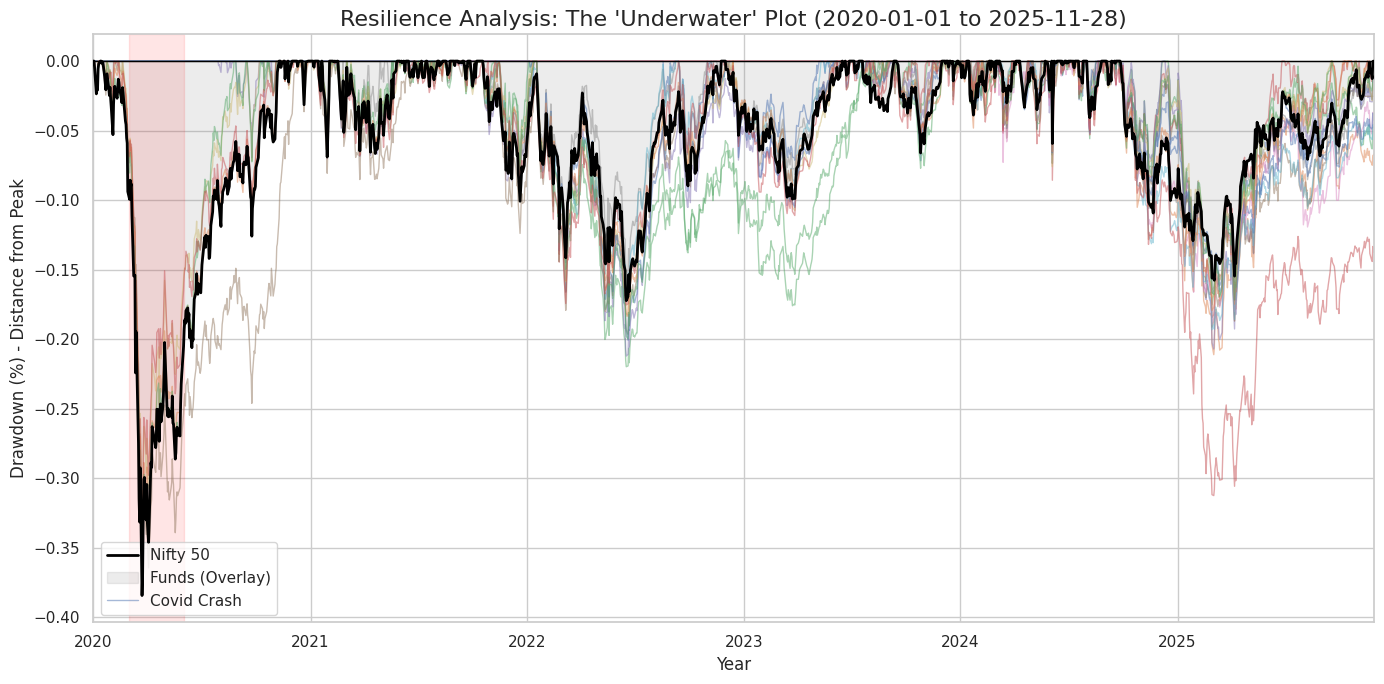

/tmp/ipython-input-1943133170.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mdd_summary['Max_Drawdown_Pct'], y=mdd_summary.index, palette=colors)


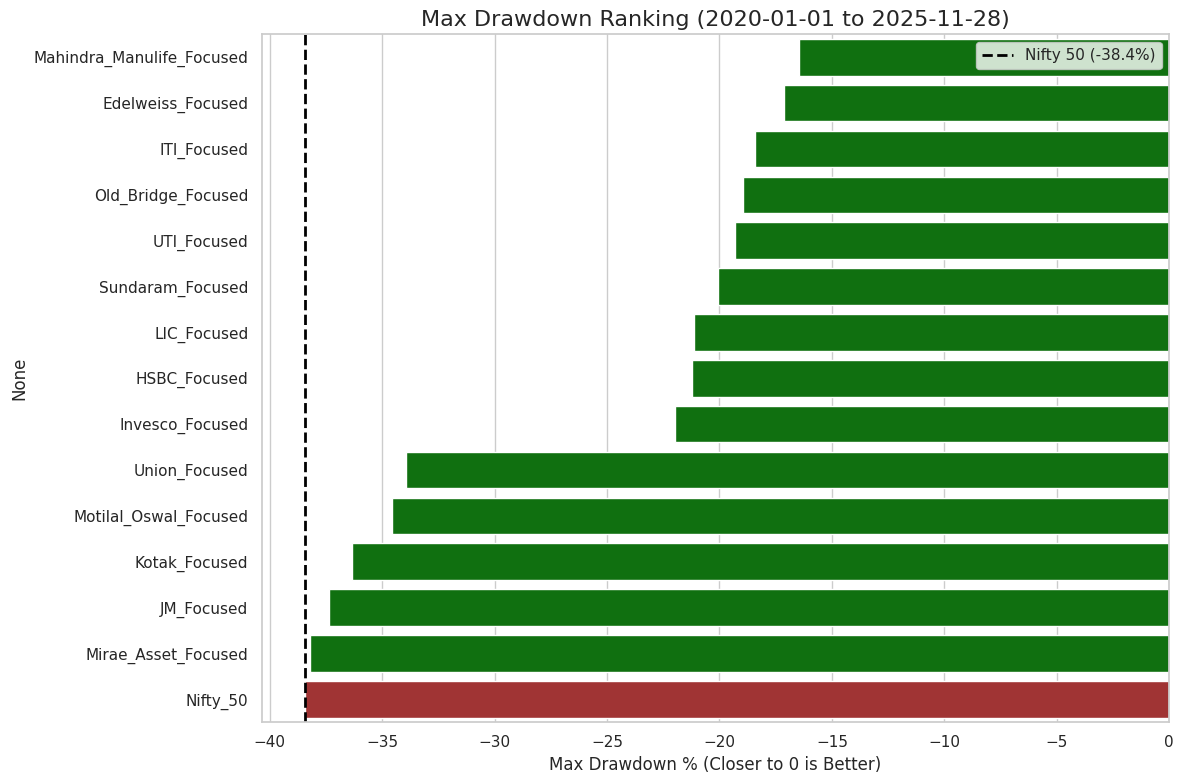


--- KEY INSIGHTS FOR REPORT ---
Benchmark (Nifty 50) Max Drawdown: -38.44%

Top 3 Most Resilient Funds (Safer than Market):
                           Max_Drawdown_Pct
Mahindra_Manulife_Focused        -16.465652
Edelweiss_Focused                -17.146170
ITI_Focused                      -18.438118

Bottom 3 Least Resilient Funds (Riskier than Market):
                     Max_Drawdown_Pct
JM_Focused                 -37.374850
Mirae_Asset_Focused        -38.216405
Nifty_50                   -38.439852


In [ ]:
sns.set_theme(style="whitegrid")
print("--- Generating Resilience Analysis ---")

#Formula:- (Current_Price - Peak_Price) / Peak_Price
rolling_peak = df_final.cummax()
drawdown = (df_final - rolling_peak) / rolling_peak
max_drawdown = drawdown.min() * 100

mdd_summary = pd.DataFrame(max_drawdown, columns=['Max_Drawdown_Pct'])
mdd_summary = mdd_summary.sort_values('Max_Drawdown_Pct', ascending=False) #Best to Worst

#--- VISUALIZATION 1: THE UNDERWATER PLOT ---
plt.figure(figsize=(14, 7))

plt.plot(drawdown.index, drawdown['Nifty_50'], color='black', linewidth=2, label='Nifty 50', zorder=10)
plt.fill_between(drawdown.index, drawdown['Nifty_50'], 0, color='gray', alpha=0.15)

for col in drawdown.columns:
    if col != 'Nifty_50':
        plt.plot(drawdown.index, drawdown[col], linewidth=1, alpha=0.5)

plt.title(f"Resilience Analysis: The 'Underwater' Plot ({start_date} to {end_date})", fontsize=16)
plt.ylabel("Drawdown (%) - Distance from Peak", fontsize=12)
plt.xlabel("Year", fontsize=12)
plt.axhline(0, color='black', linewidth=1)

plt.xlim(pd.Timestamp(start_date), pd.Timestamp(end_date))

plt.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-06-01'), color='red', alpha=0.1, label='Covid Crash')

plt.legend(['Nifty 50', 'Funds (Overlay)', 'Covid Crash'], loc='lower left')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))

nifty_val = mdd_summary.loc['Nifty_50', 'Max_Drawdown_Pct']
colors = ['green' if x > nifty_val else 'firebrick' for x in mdd_summary['Max_Drawdown_Pct']]

sns.barplot(x=mdd_summary['Max_Drawdown_Pct'], y=mdd_summary.index, palette=colors)
plt.axvline(nifty_val, color='black', linestyle='--', linewidth=2, label=f'Nifty 50 ({round(nifty_val,1)}%)')

plt.title(f"Max Drawdown Ranking ({start_date} to {end_date})", fontsize=16)
plt.xlabel("Max Drawdown % (Closer to 0 is Better)", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

print("\n--- KEY INSIGHTS FOR REPORT ---")
print(f"Benchmark (Nifty 50) Max Drawdown: {round(nifty_val, 2)}%")
print("\nTop 3 Most Resilient Funds (Safer than Market):")
print(mdd_summary[mdd_summary['Max_Drawdown_Pct'] > nifty_val].head(3))
print("\nBottom 3 Least Resilient Funds (Riskier than Market):")
print(mdd_summary.tail(3))

**Explanation:**

The resilience logic focuses on historical "Drawdowns" to measure worst-case scenarios.


*   Drawdown Algorithm: The code calculates a cumulative rolling maximum of the fund's NAV over time. The Drawdown is then computed as the percentage difference between the current price and this rolling peak.
*   Maximum Drawdown (MDD): The minimum value from the drawdown series is extracted to represent the Max Drawdown. This single number indicates the maximum percentage loss an investor would have suffered if they bought at the absolute top and sold at the absolute bottom.
*   Underwater Plot: This visualization plots the drawdown percentages over time. It visually demonstrates the depth of the fall during crises (such as the COVID-19 crash) and the duration required for the fund to recover to its previous peak.









# **3. Herding in focused funds based on holdings**

#  1. What Is Holding‑Based Herding?

Holding‑based herding measures how similarly mutual funds construct their portfolios, based on their stock holdings and allocation weights.

It answers the question:

**"Do different focused mutual funds hold the same stocks with similar weight patterns?"**

If they do, it means fund managers are likely following:

- benchmark compositions
- peer fund strategies
- market sentiment

This is especially important in focused funds, which usually hold 20–30 concentrated stocks.

#  2. Mathematical Measures Used

## A. Weighted Overlap (Portfolio Similarity)

Let:

- w_{i,k} = weight of stock k in fund i
- w_{j,k} = weight of stock k in fund j

The weighted overlap is:

```
O(i,j) = Σ min(w_{i,k}, w_{j,k})
         k=1 to K
```

### Interpretation

- If two funds hold the same stock with similar weights → high overlap
- If only one fund holds a stock → contribution = 0
- Maximum possible value = 1 (perfect similarity)

This metric captures **true portfolio similarity**, not just matching stock lists.

## B. Herding Index (Overall Herding Level)

After computing pairwise overlaps across N funds:

```
H = (2 / N(N-1)) Σ O(i,j)
                 i<j
```

### Interpretation

- **H < 0.10** → low herding
- **0.10–0.20** → moderate herding
- **> 0.20** → strong herding

##  Why Jaccard Index Is NOT Used

Jaccard Index:

```
J = |A ∩ B| / |A ∪ B|
```

considers only whether a stock is **present or absent**.

### Example:

- Fund A: ICICI Bank 9%
- Fund B: ICICI Bank 1%
- Jaccard = 1 → misleading, because weights differ massively.

Weighted Overlap gives:

```
min(9%, 1%) = 1%
```
correct representation of similarity.

**Thus, Weighted Overlap is chosen because it captures both:**

1. Common holdings
2. Similarity of allocation

Which is necessary for herding analysis.

#  3. Explanation of the Plots

##  A. Heatmap — Fund Similarity (Weighted Overlap)

**What it shows:**

- Rows → mutual funds
- Columns → mutual funds
- Darker color → higher similarity
- Lighter color → lower similarity
- Diagonal = 1 (each fund compared to itself)

**Insights:**

- Visible clusters indicate strong herding groups
- Some funds stay lighter → more independent
- Focused funds tend to cluster due to limited holdings

##  B. Top 30 Most Popular Stocks

This chart counts how many funds hold each stock in their top holdings.

**Typical observations:**

Many focused funds hold:

- ICICIBANK
- HDFCBANK
- INFY
- RELIANCE
- AXISBANK

These stocks drive most of the herding behavior.

## C. Sorted Pairwise Overlap Values

A descending scatter plot of all fund‑to‑fund overlaps.

**Interpretation:**

- Values above 0.30 → very strong similarity
- Middle region → moderate herding
- Tail near 0 → independent funds
- Smooth curve → herding is widespread, not limited to a few funds

##  D. Network Graph — Herding Connectivity

- **Nodes** = funds
- **Edges** = overlaps above threshold
- **Thicker edge** = stronger similarity
- **Larger node** = more connected (more herding)

**Interpretation:**

- Central cluster → strong herding
- Peripheral nodes → independent decision‑making
- Funds like HDFC, ICICI, Kotak often form the core cluster

---

#4. Output CSV Files

## A. holdings_matrix.csv

Matrix of:

**Fund × Ticker → weight**

Useful for:

- clustering
- PCA
- machine learning models

## B. pairwise_overlap.csv

Table of all fund‑to‑fund similarity values.

Useful for:

- ranking funds by similarity
- statistical summaries
- correlation with returns

#  5. Final Summary

The analysis reveals **moderate to strong holding‑based herding** among focused mutual funds.

Weighted overlap values indicate significant similarity in stock allocations, especially around widely held stocks like **ICICI Bank, HDFC Bank, Infosys, and Reliance**.

Both the heatmap and network graph confirm the presence of **centralized herding clusters**, with some funds consistently allocating capital in similar patterns.

The popularity chart illustrates that a small group of large‑cap stocks dominates focused fund portfolios, contributing heavily to herding behavior.

Overall, the findings show that focused mutual funds demonstrate clear cross‑sectional herding, driven by benchmark following and common stock preferences.**

/tmp/ipython-input-1406868994.py:19: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['SnapshotDate'] = pd.to_datetime(df['SnapshotDate']).dt.date


Herding Index H = 0.1473  (n_funds=28)


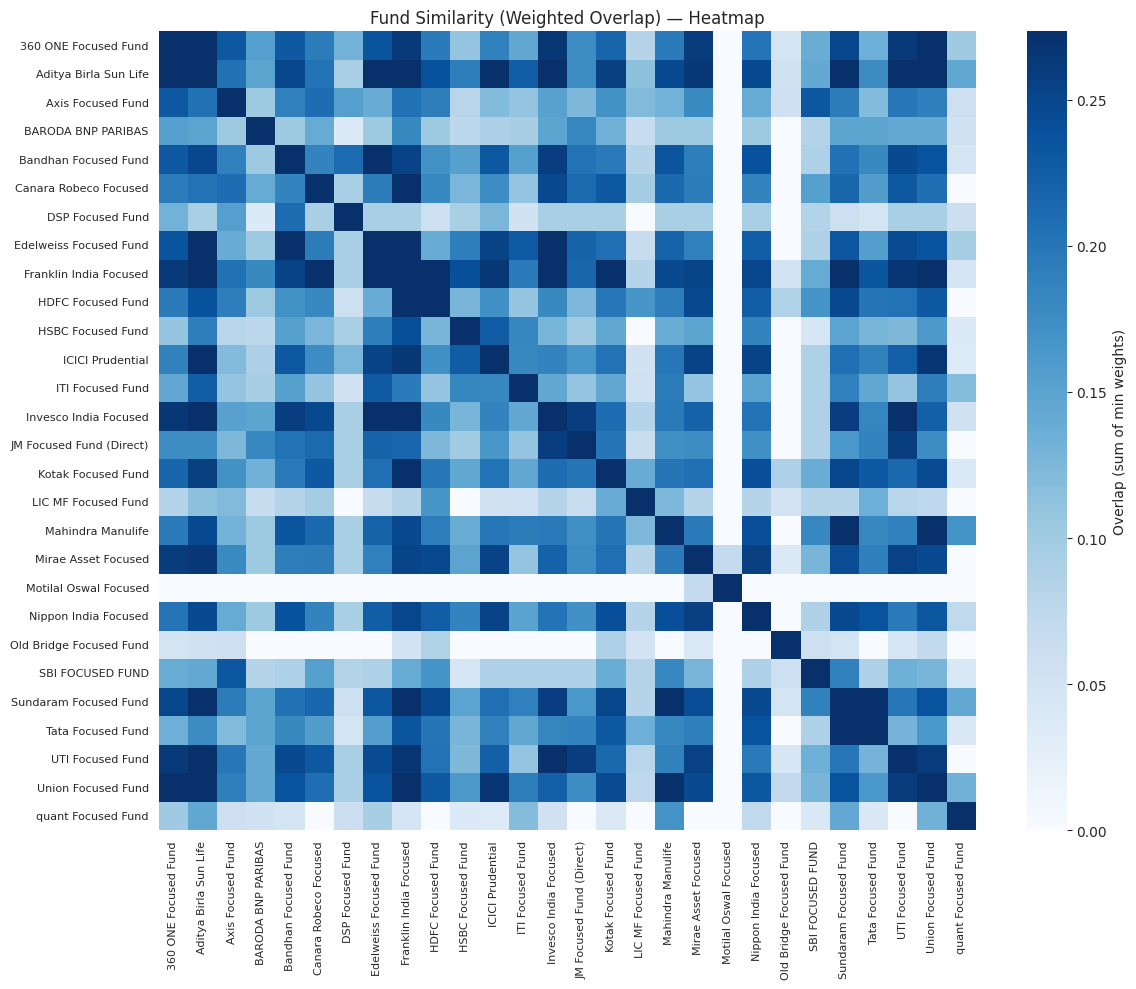

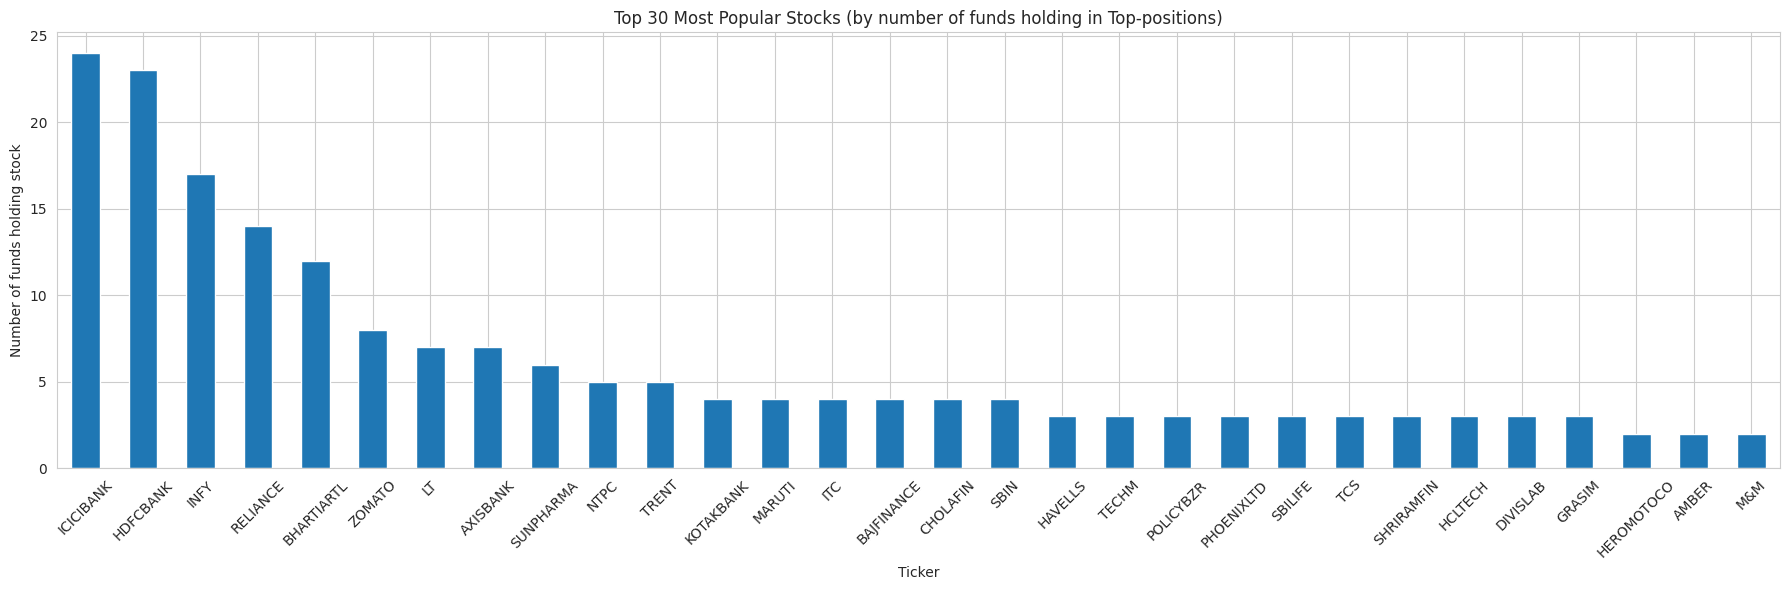

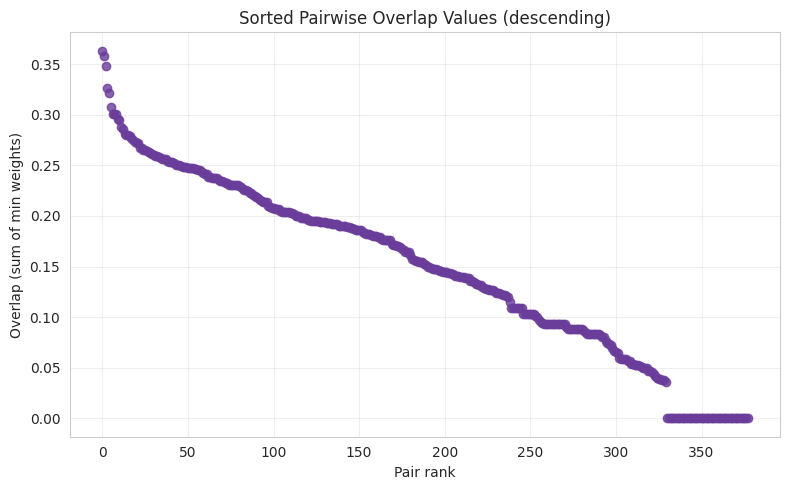

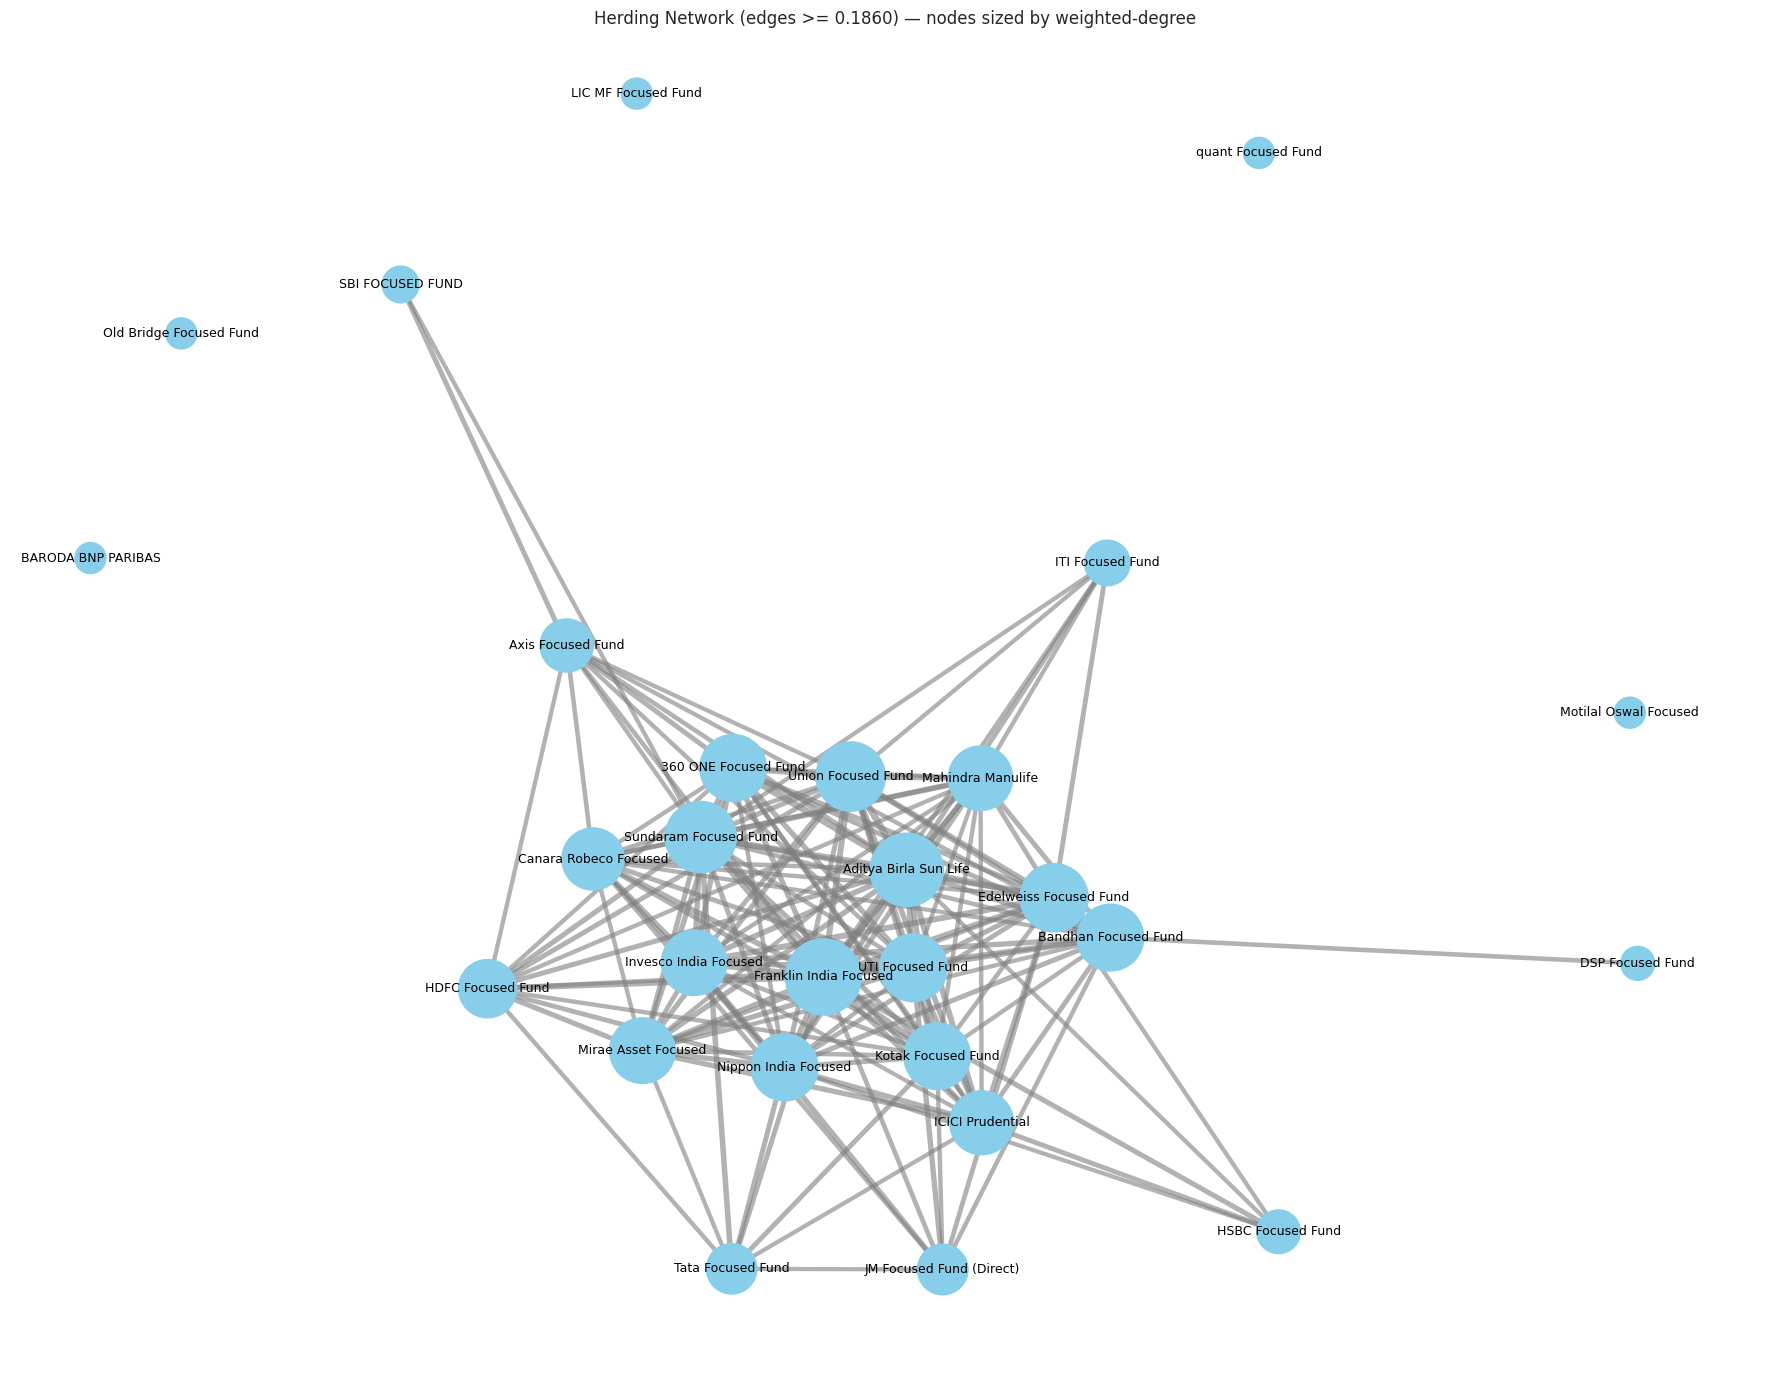


Outputs saved to: /content/herding_outputs
Key files: holdings_matrix.csv, pairwise_overlap.csv, heatmap_overlap.png, top30_stock_popularity.png, overlap_distribution.png, herding_network.png, top_fund_pairs.csv


In [ ]:
plt.style.use('default')
sns.set_style("whitegrid")

OUTDIR = "/content/herding_outputs"
os.makedirs(OUTDIR, exist_ok=True)

df = pd.read_csv('/content/holdings.csv', dtype=str)

expected = ['FundName','companyName','SchemeCode','AMC','SnapshotDate','Ticker','Weight_pct']
missing = [c for c in expected if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in holdings.csv: {missing}")

#Normalize types and columns
df['Ticker'] = df['Ticker'].str.strip().str.upper()
df['FundName'] = df['FundName'].str.strip()
df['AMC'] = df['AMC'].str.strip()
df['SchemeCode'] = df['SchemeCode'].astype(str).str.strip()
df['SnapshotDate'] = pd.to_datetime(df['SnapshotDate']).dt.date
df['Weight_pct'] = pd.to_numeric(df['Weight_pct'], errors='coerce')

df = df.dropna(subset=['Ticker','Weight_pct'])
df = df.reset_index(drop=True)

df['Weight'] = df['Weight_pct'] / 100.0

snapshots = df['SnapshotDate'].unique()
if len(snapshots) > 1:
    print("Warning: multiple SnapshotDate values found. This flow uses all rows but analysis is single-snapshot. SnapshotDates present:", snapshots)

def make_short(name, max_len=24):

    s = re.sub(r'\s*-\s*(Direct|Regular|Plan|GROWTH|Growth|DIV|Dividend).*$', '', name, flags=re.IGNORECASE)
    s = re.sub(r'\s{2,}', ' ', s).strip()

    if len(s) > max_len:
        s = s[:max_len].rsplit(' ',1)[0]
    return s

df['ShortNameBase'] = df['FundName'].apply(lambda x: make_short(x, max_len=24))

dup_counts = df.groupby('ShortNameBase')['SchemeCode'].nunique()
dups = dup_counts[dup_counts>1].index.tolist()
def ensure_unique(row):
    if row['ShortNameBase'] in dups:
        return f"{row['ShortNameBase']} ({row['SchemeCode'][-3:]})"
    return row['ShortNameBase']
df['ShortName'] = df.apply(ensure_unique, axis=1)

W = df.pivot_table(index='ShortName', columns='Ticker', values='Weight', aggfunc='sum', fill_value=0)
W = W.sort_index()
funds = W.index.tolist()
n = len(funds)
if n < 2:
    raise ValueError("Need at least two funds to compute overlaps. Found: " + str(n))

# Save holdings_matrix
W.to_csv(os.path.join(OUTDIR, 'holdings_matrix.csv'))

# Compute pairwise weighted overlap matrix O
# O[i,j] = sum_k min(w_ik, w_jk)

Wvals = W.values  # shape (n_funds, n_tickers)
O = np.zeros((n,n), dtype=float)
for i in range(n):
    # vectorized min with all funds
    wi = Wvals[i, :].reshape(1, -1)        # 1 x tickers
    mins = np.minimum(wi, Wvals)          # n x tickers
    O[i, :] = mins.sum(axis=1)

O_df = pd.DataFrame(O, index=funds, columns=funds)
O_df.to_csv(os.path.join(OUTDIR, 'pairwise_overlap.csv'))

# Herding Index H (mean pairwise overlap)
tri_idx = np.triu_indices(n, k=1)
H = (2.0 / (n*(n-1))) * O[tri_idx].sum()
print(f"Herding Index H = {H:.4f}  (n_funds={n})")


plt.figure(figsize=(12,10))
# We'll cap vmax to a sensible percentile to prevent a few large overlaps from drowning the rest
vmax = np.percentile(O[tri_idx], 95) if len(O[tri_idx])>0 else O.max()
sns.heatmap(O_df, cmap='Blues', vmax=vmax, cbar_kws={'label':'Overlap (sum of min weights)'})
plt.title("Fund Similarity (Weighted Overlap) — Heatmap")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, 'heatmap_overlap.png'), dpi=200)
plt.show()

pop = df.groupby('Ticker')['ShortName'].nunique().sort_values(ascending=False)
pop.to_csv(os.path.join(OUTDIR, 'stock_popularity.csv'), header=['n_funds'])

top_n = 30
top_pop = pop.head(top_n)
plt.figure(figsize=(18,6))
ax = top_pop.plot(kind='bar')
ax.set_title(f"Top {top_n} Most Popular Stocks (by number of funds holding in Top-positions)")
ax.set_xlabel("Ticker")
ax.set_ylabel("Number of funds holding stock")
plt.xticks(rotation=45, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, f'top{top_n}_stock_popularity.png'), dpi=200)
plt.show()


# Pairwise overlap distribution scatter

vals = O[tri_idx]
plt.figure(figsize=(8,5))
plt.scatter(np.arange(len(vals)), np.sort(vals)[::-1], color='#6a3d9a', alpha=0.8)
plt.title("Sorted Pairwise Overlap Values (descending)")
plt.ylabel("Overlap (sum of min weights)")
plt.xlabel("Pair rank")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, 'overlap_distribution.png'), dpi=200)
plt.show()


threshold = np.percentile(vals, 60)  #tune percentile (40-70) for density
G = nx.Graph()
for f in funds:
    G.add_node(f)

for i in range(n):
    for j in range(i+1, n):
        w = O[i,j]
        if w >= threshold:
            G.add_edge(funds[i], funds[j], weight=w)

wdeg = dict(G.degree(weight='weight'))
max_wdeg = max(wdeg.values()) if wdeg else 1
node_size = [500 + 2500*(wdeg.get(node,0)/max_wdeg) for node in G.nodes()]

plt.figure(figsize=(18,14))
pos = nx.spring_layout(G, k=0.7, seed=42)

edge_weights = [G[u][v]['weight'] for u,v in G.edges()]

if edge_weights:
    max_ew = max(edge_weights)
    widths = [1 + 4*(ew/max_ew) for ew in edge_weights]
else:
    widths = 1

nx.draw_networkx_edges(G, pos, width=widths, alpha=0.6, edge_color='gray')
nx.draw_networkx_nodes(G, pos, node_color='skyblue', node_size=node_size)
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title(f"Herding Network (edges >= {threshold:.4f}) — nodes sized by weighted-degree")
plt.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, 'herding_network.png'), dpi=200)
plt.show()


# Top fund pairs by overlap
pairs = []
for i in range(n):
    for j in range(i+1, n):
        pairs.append((funds[i], funds[j], O[i,j]))
pairs_sorted = sorted(pairs, key=lambda x: x[2], reverse=True)
pairs_df = pd.DataFrame(pairs_sorted, columns=['FundA','FundB','Overlap'])
pairs_df.to_csv(os.path.join(OUTDIR, 'top_fund_pairs.csv'), index=False)

summary = {
    'n_funds': n,
    'HerdingIndex_H': H,
    'edge_threshold_used': float(threshold)
}
pd.Series(summary).to_csv(os.path.join(OUTDIR, 'summary_metadata.csv'))

print("\nOutputs saved to:", OUTDIR)
print("Key files: holdings_matrix.csv, pairwise_overlap.csv, heatmap_overlap.png, top30_stock_popularity.png, overlap_distribution.png, herding_network.png, top_fund_pairs.csv")


# **4. Herding in focused funds based on returns**

# 1. What Is Returns-Based Herding?

Returns-based herding measures the collective behavior of fund managers by analyzing the daily price movements (returns) of their funds rather than their portfolio holdings.

It answers the question:
**"Do fund managers abandon their unique strategies and follow the market consensus during periods of high volatility?"**

In a normal, efficient market, as the market return becomes more extreme (very high or very low), the performance difference between funds (dispersion) should increase. However, if funds are **herding**, this dispersion shrinks because everyone is moving in the same direction as the market.

# 2. Mathematical Measures Used

## A. CSAD (Cross-Sectional Absolute Deviation)

The core metric used in this analysis is **CSAD**. It calculates the average deviation of every fund's return from the market return on a specific day.

$$CSAD_t = \frac{1}{N} \sum_{i=1}^{N} |R_{i,t} - R_{m,t}|$$

* **$R_{i,t}$**: Return of Fund $i$ on day $t$.
* **$R_{m,t}$**: Return of the Market (Nifty 50) on day $t$.
* **Interpretation**:
    * **High CSAD**: Funds are behaving differently (using their own strategies).
    * **Low CSAD**: Funds are behaving identically (clumping together).

## B. The Quadratic Regression Model (CCK Method)

To detect herding, the code tests if the relationship between Market Returns ($R_m$) and Dispersion ($CSAD$) is linear or non-linear using this regression equation:

$$CSAD_t = \alpha + \gamma_1 |R_{m,t}| + \gamma_2 (R_{m,t})^2 + \epsilon_t$$

* **$\gamma_1$ (Gamma 1)**: Measures the linear relationship. Usually positive (volatility increases dispersion).
* **$\gamma_2$ (Gamma 2)**: The **Herding Coefficient**. This is the most critical value.

### **The Logic of Gamma 2 ($\gamma_2$):**

* **Rational Market ($\gamma_2 \geq 0$):** As market returns get extreme, dispersion increases linearly. The relationship looks like a "V".
* **Herding Market ($\gamma_2 < 0$):** As market returns get extreme, funds panic and cluster around the market return, causing dispersion to decrease or flatten. The relationship looks like a frown (inverted U).

**Therefore, a negative and statistically significant $\gamma_2$ confirms the presence of herding.**

# 3. Explanation of the Code Logic

## A. Data Preparation (Windowing)
The code first cleans the data to ensure fair comparison:
1.  **NAV to Returns**: Converts absolute prices (NAV) into daily percentage changes.
2.  **Date Alignment**: It synchronizes the funds' dates with the Nifty 50 benchmark.
3.  **Window Selection**: The function `get_window_data` filters funds based on their start dates. It ensures that only "Veteran" funds (those active throughout the entire analysis period) are included, preventing skewed data from new funds entering midway.

## B. Rolling Regression
Herding is not a permanent state; it usually happens during specific crises (like the COVID crash or election volatility).
* Instead of calculating one single $\gamma_2$ for the whole 5 years, the code uses a **Rolling Window** (e.g., 22 days, 66 days).
* It moves day-by-day, calculating the $\gamma_2$ coefficient for that specific short period.
* This allows the analysis to pinpoint exactly *when* managers started herding.


# 4. Explanation of the Plots

## A. Global Scatter Plot (Market Return vs. CSAD)
**What it shows:**
* **X-Axis:** Market Return ($R_m$)
* **Y-Axis:** Dispersion ($CSAD$)
* **Red Line:** The fitted quadratic curve.

**Interpretation:**
* If the red line forms a sharp **"V" shape**, there is **no global herding**.
* If the red line curves downward (concave) at the edges, it suggests that when the market moves drastically, funds stop deviating and start copying the index.

## B. Time-Series Herding Regimes (Rolling $\gamma_2$)
**What it shows:**
* **Blue Line:** The value of the Herding Coefficient ($\gamma_2$) over time.
* **Red Shaded Area:** Periods where $\gamma_2 < 0$. These are confirmed **Herding Regimes**.
* **Green Line (Right Axis):** The cumulative market return (Nifty 50 performance).

**Insights:**
* **Red Spikes:** You will likely see deep red shaded areas during market crashes (e.g., March 2020). This indicates that during the crash, focused funds stopped picking stocks based on skill and simply moved with the market tide.
* **Market Correlation:** By comparing the Red Shaded areas with the Green Line, you can determine if herding happens more during Bull runs (Greed) or Bear runs (Fear).

# 5. Final Summary

This analysis uses the **CSAD Regression Approach** to detect behavioral anomalies in focused funds.

* **Methodology**: It tests if the dispersion of fund returns decreases during extreme market stress.
* **Key Indicator**: A negative $\gamma_2$ coefficient on the squared market return.
* **Result**: The rolling analysis visualizes specific time periods where fund managers suppressed their distinct investment styles to "herd" with the market benchmark.

In [ ]:
navs = pd.read_csv('/content/navs.csv', parse_dates=['Date'])

df_range = navs.groupby('SchemeCode').agg(
    start_date=('Date','min'),
    end_date=('Date','max'),
    n_obs=('Date','count')
).reset_index().sort_values('start_date')
df_range.to_csv('/content/nav_ranges.csv', index=False)
df_range.head(50)

,SchemeCode,start_date,end_date,n_obs
1,118564,2013-01-01,2025-12-11,3177
3,118950,2013-01-01,2025-12-11,3177
0,118421,2013-01-02,2025-12-11,3181
2,118692,2013-01-02,2025-12-11,3176
4,119096,2013-01-02,2025-12-11,3178
5,119564,2013-01-02,2025-12-11,3175
6,119727,2013-01-02,2025-12-11,3180
7,120468,2013-01-02,2025-12-11,3181
8,120488,2013-01-02,2025-12-11,3176
9,120722,2013-01-02,2025-12-11,3170


In [ ]:
plt.style.use('seaborn-v0_8-darkgrid')
pd.set_option('display.max_columns', 80)

In [ ]:
navs = pd.read_csv('/content/navs.csv', parse_dates=['Date'])
print("Total NAV rows:", len(navs))
print("Unique funds:", navs['SchemeCode'].nunique())


nav_ranges = navs.groupby('SchemeCode').agg(
    FundName=('FundName', 'first'),
    start_date=('Date', 'min'),
    end_date=('Date', 'max'),
    n_obs=('Date', 'count')
).reset_index().sort_values('start_date')

nav_ranges.to_csv('/content/nav_ranges.csv', index=False)
nav_ranges.head(50)

Total NAV rows: 57283
Unique funds: 28


,SchemeCode,FundName,start_date,end_date,n_obs
1,118564,Franklin India Focused Equity Fund - Direct - ...,2013-01-01,2025-12-11,3177
3,118950,HDFC Focused Fund - Growth Option - Direct Plan,2013-01-01,2025-12-11,3177
0,118421,Bandhan Focused Fund - Direct Plan - Growth,2013-01-02,2025-12-11,3181
2,118692,Nippon India Focused Fund - Direct Plan Growth...,2013-01-02,2025-12-11,3176
4,119096,DSP Focused Fund - Direct Plan - Growth,2013-01-02,2025-12-11,3178
5,119564,Aditya Birla Sun Life Focused Fund - Growth - ...,2013-01-02,2025-12-11,3175
6,119727,SBI FOCUSED FUND - DIRECT PLAN -GROWTH,2013-01-02,2025-12-11,3180
7,120468,Axis Focused Fund - Direct Plan - Growth Option,2013-01-02,2025-12-11,3181
8,120488,JM Focused Fund (Direct) - Growth Option,2013-01-02,2025-12-11,3176
9,120722,ICICI Prudential Focused Equity Fund - Direct ...,2013-01-02,2025-12-11,3170


In [ ]:
NAVS_PATH = '/content/navs.csv'
navs = pd.read_csv(NAVS_PATH, parse_dates=['Date'])
navs['SchemeCode'] = navs['SchemeCode'].astype(str)

def compute_nav_ranges(navs_df):
    ranges = navs_df.groupby('SchemeCode').agg(
        FundName=('FundName','first'),
        start_date=('Date','min'),
        end_date=('Date','max'),
        n_obs=('Date','count')
    ).reset_index().sort_values('start_date')
    return ranges

nav_ranges = compute_nav_ranges(navs)
nav_ranges.to_csv('/content/nav_ranges.csv', index=False)
print("Loaded navs.csv -> nav_ranges.csv saved. Funds:", len(nav_ranges))

def filter_navs_by_date(navs_df, start_date, end_date):
    """Return navs within [start_date, end_date] inclusive."""
    start = pd.to_datetime(start_date)
    end = pd.to_datetime(end_date)
    df = navs_df[(navs_df['Date'] >= start) & (navs_df['Date'] <= end)].copy()
    df['Date'] = pd.to_datetime(df['Date'])
    return df

def make_returns(navs_df):
    navs_sorted = navs_df.sort_values(['SchemeCode','Date'])
    returns = navs_sorted.groupby('SchemeCode').apply(
        lambda g: g.assign(Return = g['NAV'].pct_change())
    ).reset_index(drop=True)
    returns = returns.dropna(subset=['Return']).reset_index(drop=True)
    return returns[['Date','SchemeCode','FundName','Return']]

def select_funds_by_start(nav_ranges_df, cutoff_date):
    """Return list of SchemeCode with start_date <= cutoff_date."""
    cutoff = pd.to_datetime(cutoff_date)
    keep = nav_ranges_df[nav_ranges_df['start_date'] <= cutoff]['SchemeCode'].astype(str).tolist()
    drop  = nav_ranges_df[nav_ranges_df['start_date'] > cutoff]['SchemeCode'].astype(str).tolist()
    return keep, drop

def force_drop_latest_n(nav_ranges_df, n_drop):
    """Return list of SchemeCodes to drop: the n newest-starting funds."""
    sorted_desc = nav_ranges_df.sort_values('start_date', ascending=False)
    drop_list = sorted_desc.head(n_drop)['SchemeCode'].astype(str).tolist()
    keep_list = sorted_desc.tail(len(sorted_desc)-n_drop)['SchemeCode'].astype(str).tolist()
    return keep_list, drop_list

def get_window_data(start_date, end_date,
                    drop_by_start=True,
                    start_cutoff_for_keep=None,
                    force_drop_latest_n=None,
                    missing_frac_threshold=None,
                    save_prefix=None):
    """
    Parameters:
      - start_date, end_date: date strings (e.g. '2024-01-02')
      - drop_by_start (bool): if True, funds whose start_date > start_cutoff_for_keep (or start_date) are removed.
      - start_cutoff_for_keep: date string. If None and drop_by_start True, uses start_date parameter as cutoff.
      - force_drop_latest_n: if int, forces dropping the n newest-starting funds (overrides drop_by_start).
      - missing_frac_threshold: if set (e.g. 0.15), drop funds with >threshold missing returns after pivot.
      - save_prefix: string to prefix saved filenames; defaults to 'window_YYYYMMDD'
    Returns:
      dictionary with keys: navs_window, returns_window, returns_wide (raw), returns_wide_clean (if threshold), kept_funds, dropped_funds
    """
    start = pd.to_datetime(start_date)
    end = pd.to_datetime(end_date)
    if save_prefix is None:
        save_prefix = f"window_{start.strftime('%Y%m%d')}_{end.strftime('%Y%m%d')}"
    os.makedirs('/content', exist_ok=True)

    navs_w = filter_navs_by_date(navs, start, end)

    nav_ranges_local = compute_nav_ranges(navs)
    if force_drop_latest_n is not None:
        keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)
        keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)

        keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)
        keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)

        keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)

        keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)

        if force_drop_latest_n is not None:
            keep_codes, drop_codes = force_drop_latest_n and force_drop_latest_n or (None,None)
    if force_drop_latest_n is not None:
        keep_codes, drop_codes = force_drop_latest_n_call(nav_ranges_local, force_drop_latest_n)
    else:
        if drop_by_start:
            cutoff = pd.to_datetime(start_cutoff_for_keep) if start_cutoff_for_keep is not None else start
            keep_codes, drop_codes = select_funds_by_start(nav_ranges_local, cutoff)
        else:

            keep_codes = sorted(navs_w['SchemeCode'].unique().astype(str).tolist())
            drop_codes = [c for c in sorted(navs['SchemeCode'].unique().astype(str).tolist()) if c not in keep_codes]

    navs_w = navs_w[navs_w['SchemeCode'].astype(str).isin(keep_codes)].copy()
    navs_out = f"/content/{save_prefix}_navs.csv"
    navs_w.to_csv(navs_out, index=False)

    returns_w = make_returns(navs_w)
    returns_out = f"/content/{save_prefix}_returns.csv"
    returns_w.to_csv(returns_out, index=False)

    R_wide = returns_w.pivot(index='Date', columns='SchemeCode', values='Return').sort_index()
    R_wide_out = f"/content/{save_prefix}_returns_wide_raw.csv"
    R_wide.to_csv(R_wide_out)

    kept_after_missing = keep_codes.copy()
    dropped_due_to_missing = []
    R_wide_clean = None
    if missing_frac_threshold is not None:
        miss_frac = R_wide.isna().mean().sort_values()
        keep_cols = list(miss_frac[miss_frac <= missing_frac_threshold].index)
        drop_cols = list(miss_frac[miss_frac > missing_frac_threshold].index)

        R_wide_clean = R_wide[keep_cols].copy()


        R_wide_clean = R_wide_clean.dropna(axis=0, how='any')


        R_wide_clean.to_csv(f"/content/{save_prefix}_returns_wide_clean.csv")
        print("Saved cleaned wide returns with NO missing rows.")

        dropped_due_to_missing = drop_cols
        kept_after_missing = keep_cols

    pd.DataFrame({'SchemeCode': keep_codes}).to_csv(f"/content/{save_prefix}_kept_funds.csv", index=False)
    pd.DataFrame({'SchemeCode': drop_codes}).to_csv(f"/content/{save_prefix}_dropped_funds.csv", index=False)

    out = {
        'navs_window': navs_w,
        'returns_window': returns_w,
        'returns_wide_raw': R_wide,
        'returns_wide_clean': R_wide_clean,
        'kept_funds': keep_codes,
        'dropped_funds': drop_codes,
        'dropped_due_to_missing': dropped_due_to_missing,
        'saved_files_prefix': save_prefix
    }
    print(f"Saved: {navs_out}, {returns_out}, {R_wide_out}")
    if R_wide_clean is not None:
        print(f"Saved cleaned wide returns -> /content/{save_prefix}_returns_wide_clean.csv")
    return out

def force_drop_latest_n_call(nav_ranges_df, n_drop):
    sorted_desc = nav_ranges_df.sort_values('start_date', ascending=False).reset_index(drop=True)
    drop_list = sorted_desc.head(n_drop)['SchemeCode'].astype(str).tolist()
    keep_list = sorted_desc.tail(len(sorted_desc)-n_drop)['SchemeCode'].astype(str).tolist()
    return keep_list, drop_list


resA = get_window_data('2024-01-01', '2025-11-30',
                       drop_by_start=True,

                       start_cutoff_for_keep='2024-01-01',
                       missing_frac_threshold=0.40,
                       save_prefix='WindowA_allFunds')

resB = get_window_data('2019-12-12', '2025-11-30',
                       drop_by_start=True,
                       start_cutoff_for_keep='2019-12-12',
                       missing_frac_threshold=0.15,
                       save_prefix='WindowB_longSample')

Loaded navs.csv -> nav_ranges.csv saved. Funds: 28


/tmp/ipython-input-3737945488.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  returns = navs_sorted.groupby('SchemeCode').apply(


Saved cleaned wide returns with NO missing rows.
Saved: /content/WindowA_allFunds_navs.csv, /content/WindowA_allFunds_returns.csv, /content/WindowA_allFunds_returns_wide_raw.csv
Saved cleaned wide returns -> /content/WindowA_allFunds_returns_wide_clean.csv


/tmp/ipython-input-3737945488.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  returns = navs_sorted.groupby('SchemeCode').apply(


Saved cleaned wide returns with NO missing rows.
Saved: /content/WindowB_longSample_navs.csv, /content/WindowB_longSample_returns.csv, /content/WindowB_longSample_returns_wide_raw.csv
Saved cleaned wide returns -> /content/WindowB_longSample_returns_wide_clean.csv


In [ ]:
def get_benchmark(index="^NSEI", start="2010-01-01", end="2030-01-01"):
    df = yf.download(index, start=start, end=end)[['Close']]
    df = df.rename(columns={'Close':'IndexClose'})
    df['Date'] = pd.to_datetime(df.index).date
    df['IndexReturn'] = df['IndexClose'].pct_change()
    df = df.dropna()
    return df[['Date', 'IndexReturn']]

In [ ]:
def align_returns_with_benchmark(R_wide_clean, benchmark):

    R = R_wide_clean.copy()
    R.index = pd.to_datetime(R.index)

    b = benchmark.copy()
    b['Date'] = pd.to_datetime(b['Date'])

    common = sorted(list(set(R.index.date).intersection(set(b['Date'].dt.date))))
    common_dt = pd.to_datetime(common)

    R_aligned = R.loc[common_dt].copy()
    mkt = b.set_index('Date').loc[common_dt, 'IndexReturn']

    return R_aligned, mkt

In [ ]:
try:

    R_wide = pd.read_csv('/content/WindowB_longSample_returns_wide_clean.csv', index_col='Date')
except FileNotFoundError:
    print("File not found! Please ensure you ran 'get_window_data' with save_prefix='WindowB_longSample'")

    R_wide = pd.DataFrame()

if not R_wide.empty:
    bench_df = get_benchmark(start="2019-01-01", end="2025-12-31")
    R_aligned, mkt_series = align_returns_with_benchmark(R_wide, bench_df)
    csad_series = (R_aligned.sub(mkt_series, axis=0).abs()).mean(axis=1)

    df_ana = pd.DataFrame({
        'Rm': mkt_series,
        'Abs_Rm': mkt_series.abs(),
        'Rm_Sq': mkt_series ** 2,
        'CSAD': csad_series
    })

    df_ana['Cumulative_Rm'] = (1 + df_ana['Rm']).cumprod()

    print(f"Data Aligned. Trading Days: {len(df_ana)}")
    print(df_ana.head())
else:
    print("Cannot proceed without input CSV.")

/tmp/ipython-input-2173156575.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(index, start=start, end=end)[['Close']]
[*********************100%***********************]  1 of 1 completed

Data Aligned. Trading Days: 1283
                  Rm    Abs_Rm     Rm_Sq      CSAD  Cumulative_Rm
2019-12-13  0.009598  0.009598  0.000092  0.002184       1.009598
2019-12-16 -0.002710  0.002710  0.000007  0.001944       1.006862
2019-12-17  0.009213  0.009213  0.000085  0.002736       1.016138
2019-12-18  0.004657  0.004657  0.000022  0.003494       1.020870
2019-12-19  0.003113  0.003113  0.000010  0.001589       1.024048


In [ ]:
WINDOWS = [22, 66, 132]

results_store = {}

print("Starting Rolling Regression...")

for w in WINDOWS:
    print(f"Processing Window: {w} days...")

    gamma2_list = []
    t_stat_list = []
    dates_list = []

    for i in range(w, len(df_ana)):

        sub_df = df_ana.iloc[i-w : i]

        Y = sub_df['CSAD']
        X = sub_df[['Abs_Rm', 'Rm_Sq']]
        X = sm.add_constant(X)

        try:

            model = sm.OLS(Y, X).fit()
            g2 = model.params['Rm_Sq']
            t_stat = model.tvalues['Rm_Sq']

            gamma2_list.append(g2)
            t_stat_list.append(t_stat)
            dates_list.append(df_ana.index[i])
        except:
            gamma2_list.append(np.nan)
            t_stat_list.append(np.nan)
            dates_list.append(df_ana.index[i])

    res_df = pd.DataFrame(
        {
            'Gamma2': gamma2_list,
            'T_Stat': t_stat_list
        }, index=dates_list)

    results_store[w] = res_df

print("Rolling Analysis Complete.")

Starting Rolling Regression...
Processing Window: 22 days...
Processing Window: 66 days...
Processing Window: 132 days...
Rolling Analysis Complete.


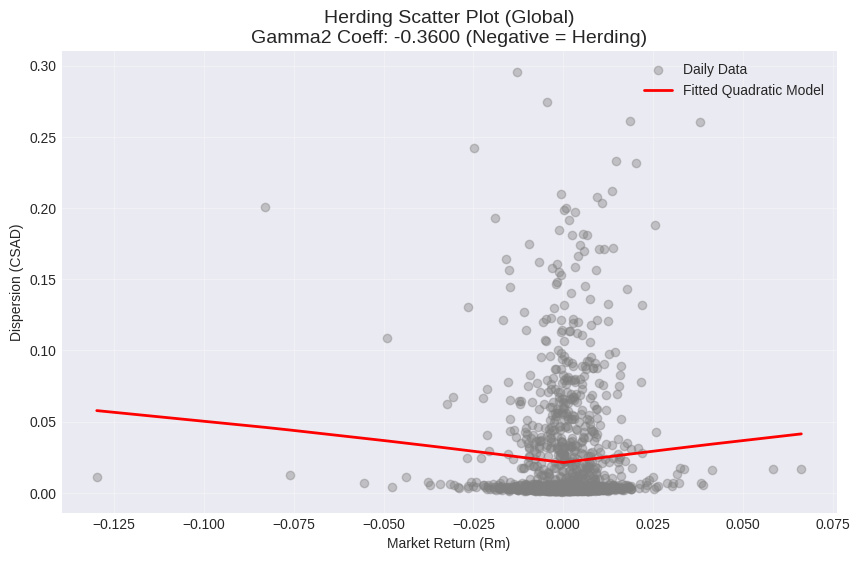

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


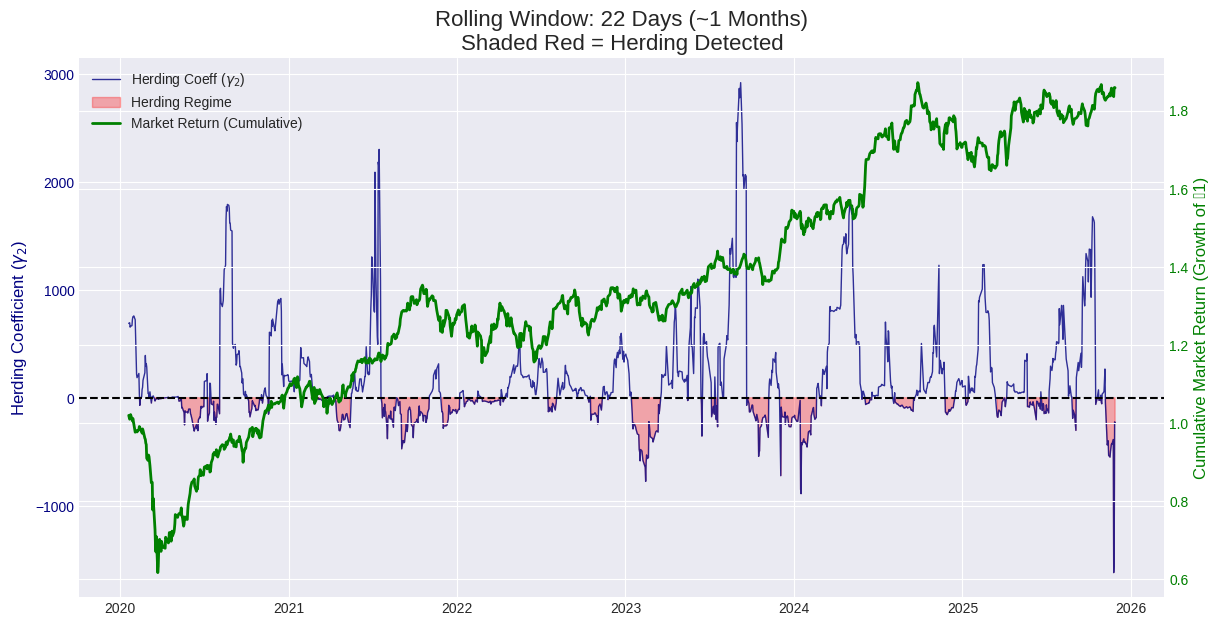

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


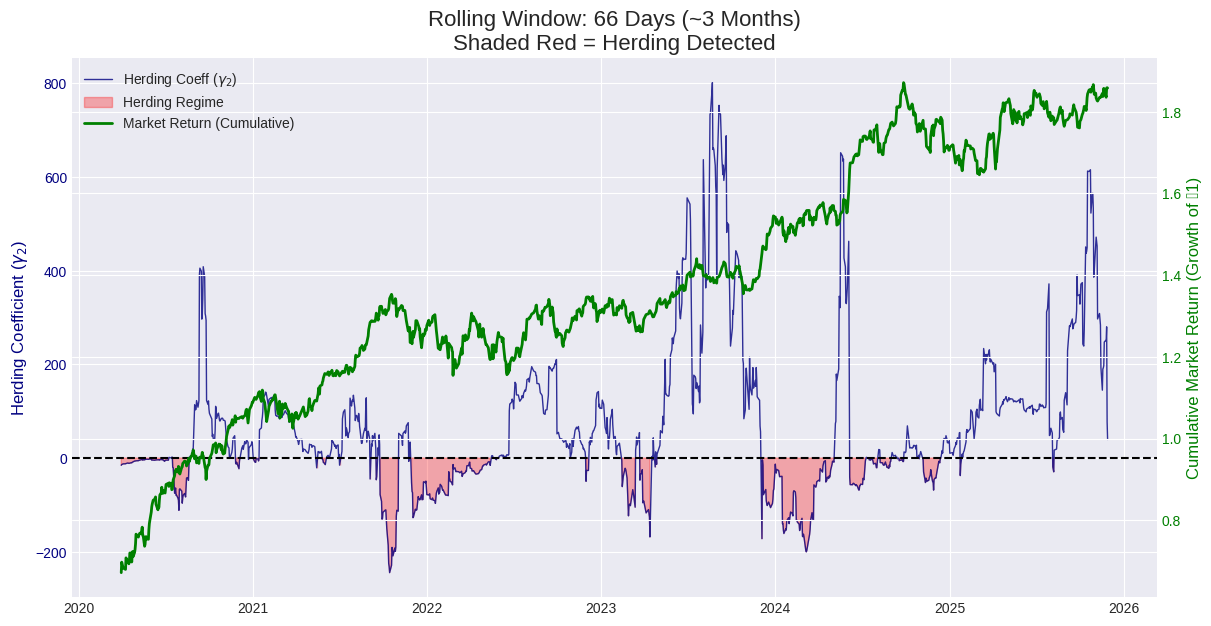

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


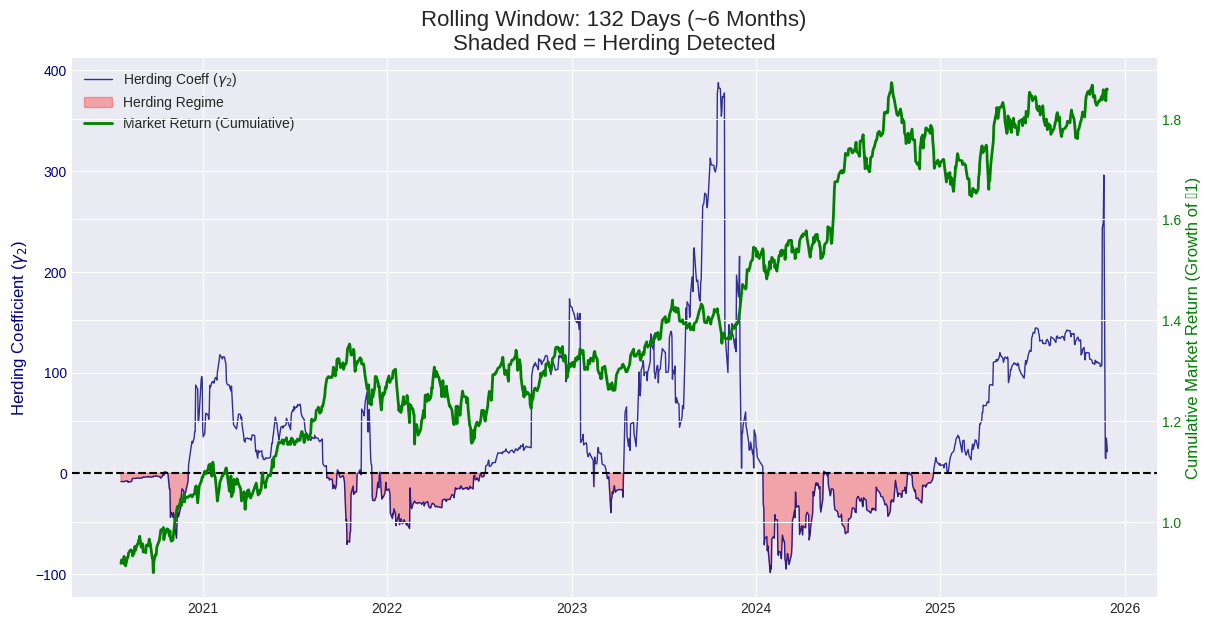

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(df_ana['Rm'], df_ana['CSAD'], alpha=0.4, color='gray', label='Daily Data')

sort_idx = np.argsort(df_ana['Rm'])
X_sorted = df_ana[['Abs_Rm', 'Rm_Sq']].iloc[sort_idx]
X_sorted = sm.add_constant(X_sorted)
Y_sorted = df_ana['CSAD'].iloc[sort_idx]

global_model = sm.OLS(df_ana['CSAD'], sm.add_constant(df_ana[['Abs_Rm', 'Rm_Sq']])).fit()
preds = global_model.predict(X_sorted)

plt.plot(df_ana['Rm'].iloc[sort_idx], preds, color='red', linewidth=2, label='Fitted Quadratic Model')

plt.title(f"Herding Scatter Plot (Global)\nGamma2 Coeff: {global_model.params['Rm_Sq']:.4f} (Negative = Herding)", fontsize=14)
plt.xlabel("Market Return (Rm)")
plt.ylabel("Dispersion (CSAD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for w in WINDOWS:
    if w not in results_store: continue

    data = results_store[w]

    combined = data.join(df_ana[['Cumulative_Rm']], how='inner')

    fig, ax1 = plt.subplots(figsize=(14, 7))

    ax1.plot(combined.index, combined['Gamma2'], color='navy', linewidth=1, alpha=0.8, label=r'Herding Coeff ($\gamma_2$)')
    ax1.axhline(0, color='black', linestyle='--')


    ax1.fill_between(combined.index, combined['Gamma2'], 0,
                     where=(combined['Gamma2'] < 0), color='red', alpha=0.3, label='Herding Regime')

    ax1.set_ylabel(r'Herding Coefficient ($\gamma_2$)', color='navy', fontsize=12)
    ax1.tick_params(axis='y', labelcolor='navy')
    ax1.set_title(f"Rolling Window: {w} Days (~{int(w/22)} Months)\nShaded Red = Herding Detected", fontsize=16)


    ax2 = ax1.twinx()
    ax2.plot(combined.index, combined['Cumulative_Rm'], color='green', linewidth=2, label='Market Return (Cumulative)')
    ax2.set_ylabel('Cumulative Market Return (Growth of ₹1)', color='green', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='green')


    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

    plt.show()